# Exploração Inicial dos Dados

- **Projeto:** Recuperação da Confiabilidade dos Dados de Vendas
- **Etapa:** Diagnóstico e entendimento da base bruta
- **Dataset:** [Cafe Sales - Dirty Data for Cleaning Training](https://www.kaggle.com/datasets/ahmedmohamed2003/cafe-sales-dirty-data-for-cleaning-training)
- **Próximo notebook:** [02_data_preparation.ipynb](02_data_preparation.ipynb)

Este notebook faz uma EDA inicial para diagnosticar a base de vendas: estrutura, tipos, identificador, datas e valores ausentes ou inválidos.

**Sumário:**

1. Carga e estrutura da base
2. Valores distintos por coluna
3. ID de transação (`transaction_id`)
4. Datas (`transaction_date`)
5. Sujeira nos dados
6. Achados

In [1]:
import pandas as pd

from src import load_raw_sales, calculate_df, dirty_graphics, dirty_mask

## 1. Carga e estrutura do dataset

A função `load_raw_sales` lê o CSV bruto e padroniza os nomes das colunas para *snake_case*, evitando espaços e maiúsculas no código. 

In [2]:
df = load_raw_sales('dirty_cafe_sales')
df.head()

,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


### 1.2 Retornando as dimensões do DataFrame

In [3]:
print(f"Total de linhas: {df.shape[0]}")
print(f"Total de colunas: {df.shape[1]}")

Total de linhas: 10000
Total de colunas: 8


### 1.3 Verificando as informações do DataFrame

In [4]:
df.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   transaction_id    10000 non-null  str  
 1   item              9667 non-null   str  
 2   quantity          9862 non-null   str  
 3   price_per_unit    9821 non-null   str  
 4   total_spent       9827 non-null   str  
 5   payment_method    7421 non-null   str  
 6   location          6735 non-null   str  
 7   transaction_date  9841 non-null   str  
dtypes: str(8)
memory usage: 1.1 MB


## 2. Valores distintos por coluna

Por conta da grande quantidade de valores nas colunas `transaction_id` e `transaction_data`, elas serão verificadas individualmente.

### 2.1 Quantidade de valores únicos

In [5]:
df.nunique(dropna=False)

transaction_id      10000
item                   11
quantity                8
price_per_unit          9
total_spent            20
payment_method          6
location                5
transaction_date      368
dtype: int64

### 2.2 Frequência dos valores

In [6]:
for col in df.columns.drop(['transaction_id', 'transaction_date']):
    print(f'{df[col].value_counts(dropna=False).to_string()}\n')

item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
UNKNOWN      344
NaN          333
ERROR        292

quantity
5          2013
2          1974
4          1863
3          1849
1          1822
UNKNOWN     171
ERROR       170
NaN         138

price_per_unit
3.0        2429
4.0        2331
2.0        1227
5.0        1204
1.0        1143
1.5        1133
ERROR       190
NaN         179
UNKNOWN     164

total_spent
6.0        979
12.0       939
3.0        930
4.0        923
20.0       746
15.0       734
8.0        677
10.0       524
2.0        497
9.0        479
5.0        468
16.0       444
25.0       259
7.5        237
1.0        232
4.5        225
1.5        205
NaN        173
UNKNOWN    165
ERROR      164

payment_method
NaN               2579
Digital Wallet    2291
Credit Card       2273
Cash              2258
ERROR              306
UNKNOWN            293

location
NaN         3265
Takeaway    3022

### 2.3 Máscara de sujeira

Na seção anterior, foi identificado 2 padrões que representam valores ausentes: `ERROR` e `UNKNOWN`. Com isso, vamos padronizá-los em uma variável booleana para facilitar a investigação antes da limpeza dos dados.

> **Células totais** = linhas x colunas 

In [7]:
dirty_values = dirty_mask(df)
n_dirty = dirty_values.sum().sum()

print(f'Células sujas: {n_dirty} de {df.size}, cerca de {n_dirty / df.size:.1%}')

Células sujas: 10082 de 80000, cerca de 12.6%


## 3. ID de transação (`transaction_id`)

### 3.1 Granularidade do ID

Testa se cada linha de ID é uma transação distinta.

| Resultado | Significado | Diagnóstico |
|:--|:--|:--|
| `= 1.0` |  IDs distintas | Uma linha por venda |
| `< 1.0`|  IDs repetidos | Múltiplos itens por venda |

In [8]:
print(f"Total de IDs distintos: {df['transaction_id'].nunique()}")
print(f"Granularidade do ID: {df['transaction_id'].nunique() / len(df)}")

Total de IDs distintos: 10000
Granularidade do ID: 1.0


### 3.2 Padrão e valores sujos

O ID segue o padrão `TXN_` seguido de 7 dígitos (11 caracteres).

In [9]:
n_pattern = df['transaction_id'].str.fullmatch(r'TXN_\d{7}').sum()

print(f'IDs no padrão TXN_ + 7 dígitos: {n_pattern} de {len(df)}')
print(f"IDs com valor sujo: {dirty_values['transaction_id'].sum()}")

IDs no padrão TXN_ + 7 dígitos: 10000 de 10000
IDs com valor sujo: 0


## 4. Datas (`transaction_date`)

### 4.1 Formato das datas válidas

Antes de comparar ou ordenar as datas , é preciso confirmar que todas as datas válidas seguem o mesmo formato `AAAA-MM-DD`.

In [10]:
valid_dates = df.loc[~dirty_values['transaction_date'], 'transaction_date']
standard_date = valid_dates.str.fullmatch(r'\d{4}-\d{2}-\d{2}').sum()

print(f'Datas válidas: {len(valid_dates)}')
print(f'Datas no formato AAAA-MM-DD: {standard_date}')

Datas válidas: 9540
Datas no formato AAAA-MM-DD: 9540


### 4.2 Valores distintos

In [11]:
print(f'Total de datas distintas: {df['transaction_date'].nunique(dropna=False)}')
print(f'Total de datas válidas: {valid_dates.nunique()}')

Total de datas distintas: 368
Total de datas válidas: 365


### 4.3 Intervalo de datas

Importante para entender qual o intervalo temporal das vendas;

In [12]:
print(f'Primeira data: {valid_dates.min()}')
print(f'Última data: {valid_dates.max()}')

Primeira data: 2023-01-01
Última data: 2023-12-31


## 5. Sujeiras no dataset

Como dito anteriormente, foi constatado que `ERROR` e `UNKNOWN` funcionam como valores ausentes, assim como o `NaN`. Pensando nisso, vamos verificar a taxa percentual de linhas sujas no DataFrame.

### 5.1 `NaN`

In [13]:
df_nan = calculate_df(df=df, column_name='total', aggregation=df.isna().sum())
df_nan

,total,%
location,3265,32.65
payment_method,2579,25.79
item,333,3.33
price_per_unit,179,1.79
total_spent,173,1.73
transaction_date,159,1.59
quantity,138,1.38
transaction_id,0,0.00


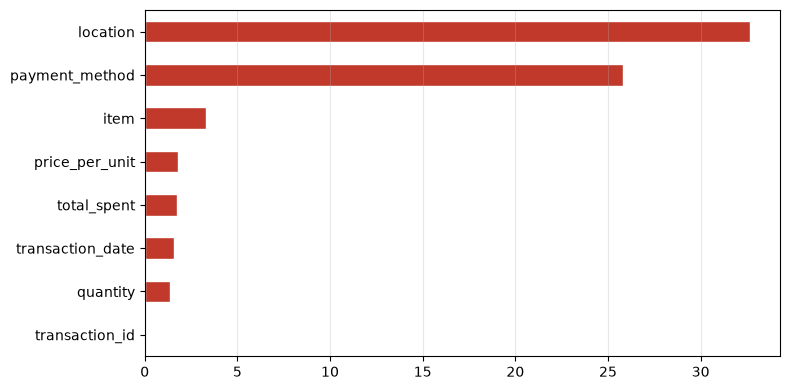

In [14]:
# O ponto e vírgula (;) não exibe o retorno da função
dirty_graphics(df=df_nan, column_name='%', kind='barh', color='#c0392b');

### 5.2 `ERROR`

In [15]:
df_error = calculate_df(df=df, column_name='total', aggregation=(df == 'ERROR').sum())
df_error

,total,%
location,358,3.58
payment_method,306,3.06
item,292,2.92
price_per_unit,190,1.90
quantity,170,1.70
total_spent,164,1.64
transaction_date,142,1.42
transaction_id,0,0.00


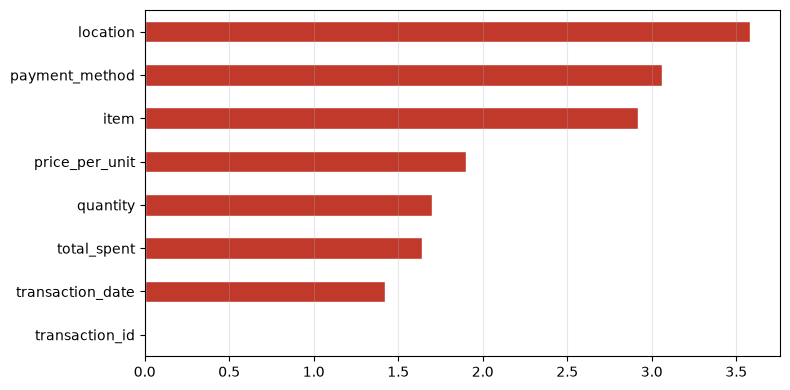

In [16]:
dirty_graphics(df=df_error, column_name='%', kind='barh', color='#c0392b');

### 5.3 `UNKNOWN`

In [17]:
df_unknown = calculate_df(df=df, column_name='total', aggregation=(df == 'UNKNOWN').sum())
df_unknown

,total,%
item,344,3.44
location,338,3.38
payment_method,293,2.93
quantity,171,1.71
total_spent,165,1.65
price_per_unit,164,1.64
transaction_date,159,1.59
transaction_id,0,0.00


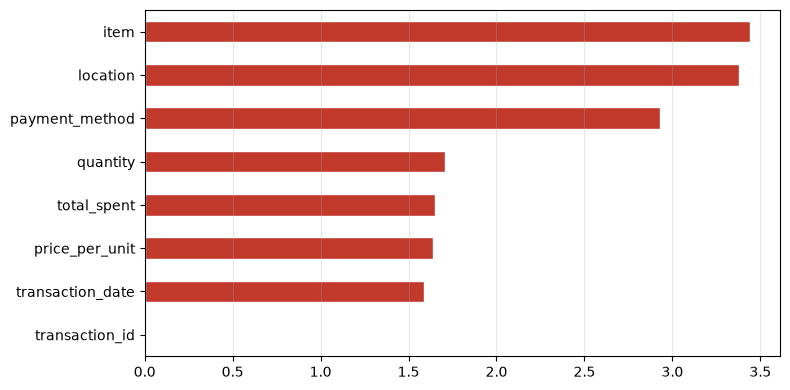

In [18]:
dirty_graphics(df=df_unknown, column_name='%', kind='barh', color='#c0392b');

### 5.4 Comparativo entre os três tipos

A tabela abaixo coloca lado a lado a proporção de cada tipo de sujeira encontrado na base de dados para uma comparação mais ilustrativa. É possível notar que o `NaN` em `location` e `payment_method` é consideravelmente maior que nas outras colunas.

In [19]:
dirty_total = pd.DataFrame({
    'NaN': df_nan['%'],
    'ERROR': df_error['%'],
    'UNKNOWN': df_unknown['%'],
})

dirty_total['total'] = dirty_total.sum(axis=1)
dirty_total.sort_values('total', ascending=False)

,NaN,ERROR,UNKNOWN,total
location,32.65,3.58,3.38,39.61
payment_method,25.79,3.06,2.93,31.78
item,3.33,2.92,3.44,9.69
price_per_unit,1.79,1.90,1.64,5.33
total_spent,1.73,1.64,1.65,5.02
quantity,1.38,1.70,1.71,4.79
transaction_date,1.59,1.42,1.59,4.60
transaction_id,0.00,0.00,0.00,0.00


### 5.5 Sujeira total

Soma dos 3 tipos por coluna.

In [20]:
df_dirty = calculate_df(df=df, column_name='total', aggregation=dirty_values.sum())
df_dirty

,total,%
location,3961,39.61
payment_method,3178,31.78
item,969,9.69
price_per_unit,533,5.33
total_spent,502,5.02
quantity,479,4.79
transaction_date,460,4.60
transaction_id,0,0.00


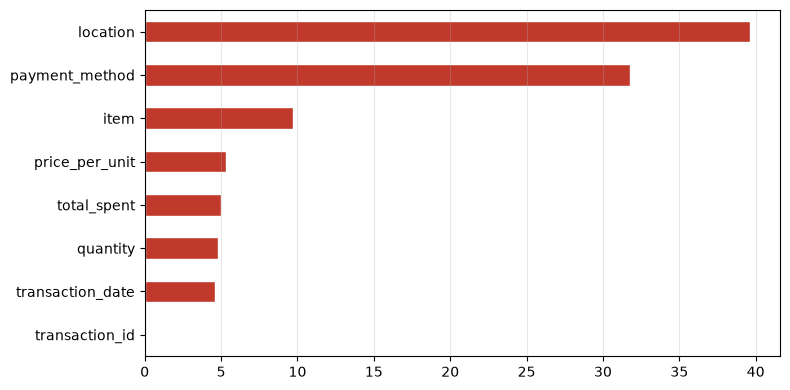

In [21]:
dirty_graphics(df=df_dirty, column_name='%', kind='barh', color='#c0392b');

### 5.6 Linhas com totalmente sujas

Linhas que estão sujas em todas colunas, exceto na já verificada `transaction_id`.

In [22]:
print(f'Linhas totalmente sujas: {dirty_values.drop(columns=['transaction_id']).all(axis=1).sum()}')

Linhas totalmente sujas: 0


### 5.7 Linhas por quantidade de colunas sujas

O índice da tabela indica quantas colunas de uma linha estão sujas. A linha `0` mostra as linhas sem nenhuma coluna suja.

In [23]:
df_lines = calculate_df(
    df=df,
    aggregation=dirty_values.sum(axis=1).value_counts(),
    column_name='lines',
).sort_index()

df_lines

,lines,%
0,3089,30.89
1,4285,42.85
2,2136,21.36
3,439,4.39
4,47,0.47
5,4,0.04


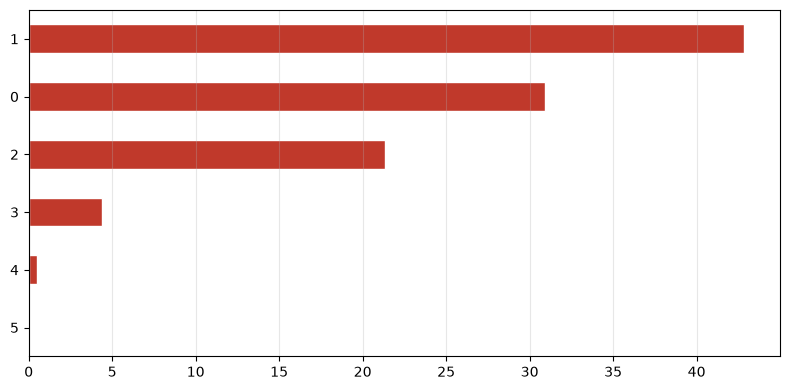

In [24]:
dirty_graphics(df=df_lines, column_name='%', kind='barh', color='#c0392b');

## 6. Achados 

- **Estrutura:** 10.000 linhas e 8 colunas, todas lidas como texto.
- **Identificador:** `transaction_id` é único, está 100% no padrão `TXN_` + 7 dígitos e não tem nenhuma linha suja.
- **Datas:** 365 datas válidas distintas, de 2023-01-01 a 2023-12-31, todas em `AAAA-MM-DD`.
- **Volume de sujeira:** 10.082 de 80.000 células, cerca de 12.6%.
- **Por coluna:** `location` 39.61%, `payment_method` 31.78% e `item` 9.69%; `price_per_unit`, `total_spent`, `quantity` e `transaction_date` entre 4.60% e 5.33%.
- **Natureza da sujeira:** em `location` e `payment_method`, o `NaN` é de 8 a 10 vezes maior que `ERROR` ou `UNKNOWN`; nas demais colunas, os três tipos têm uma taxa parecida de entre 1.4% a 3.4% cada.
- **Por linha:** 30,89% das linhas estão sem sujeira, 42,85% têm uma coluna suja e nenhuma está totalmente suja. O máximo é 5 colunas sujas.